In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 고객 분석용 데이터 불러오기
df = pd.read_csv(
    "output/rfm_clean.csv",
    dtype={"CustomerID": str}
)

# 날짜형 변환
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("데이터 크기:", df.shape)
print("고객 수:", df["CustomerID"].nunique())

df.head()


데이터 크기: (392692, 9)
고객 수: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [2]:

# 각 거래가 발생한 월
df["OrderMonth"] = (
    df["InvoiceDate"].dt.to_period("M")
)

# 고객별 첫 구매 월
df["CohortMonth"] = (
    df.groupby("CustomerID")["OrderMonth"]
    .transform("min")
)

df[
    ["CustomerID", "OrderMonth", "CohortMonth"]
].head(10)


,CustomerID,OrderMonth,CohortMonth
0,17850,2010-12,2010-12
1,17850,2010-12,2010-12
2,17850,2010-12,2010-12
3,17850,2010-12,2010-12
4,17850,2010-12,2010-12
5,17850,2010-12,2010-12
6,17850,2010-12,2010-12
7,17850,2010-12,2010-12
8,17850,2010-12,2010-12
9,13047,2010-12,2010-12


In [3]:

# 첫 구매 월부터 경과한 개월 수
df["CohortIndex"] = (
    (df["OrderMonth"].dt.year -
     df["CohortMonth"].dt.year) * 12
    +
    (df["OrderMonth"].dt.month -
     df["CohortMonth"].dt.month)
)

# 첫 구매 월을 1개월 차로 표시
df["CohortIndex"] += 1

df[
    ["CustomerID", "CohortMonth",
     "OrderMonth", "CohortIndex"]
].head(10)


,CustomerID,CohortMonth,OrderMonth,CohortIndex
0,17850,2010-12,2010-12,1
1,17850,2010-12,2010-12,1
2,17850,2010-12,2010-12,1
3,17850,2010-12,2010-12,1
4,17850,2010-12,2010-12,1
5,17850,2010-12,2010-12,1
6,17850,2010-12,2010-12,1
7,17850,2010-12,2010-12,1
8,17850,2010-12,2010-12,1
9,13047,2010-12,2010-12,1


In [4]:

# 코호트별 월별 구매 고객 수
cohort_data = (
    df.groupby(["CohortMonth", "CohortIndex"])
    ["CustomerID"]
    .nunique()
    .reset_index()
)

# 가로형 표 만들기
cohort_table = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

cohort_table


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:

# 각 코호트의 최초 고객 수
cohort_size = cohort_table.iloc[:, 0]

# 최초 고객 수 대비 월별 구매 고객 비율
retention = cohort_table.divide(
    cohort_size,
    axis=0
) * 100

retention.round(2)


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


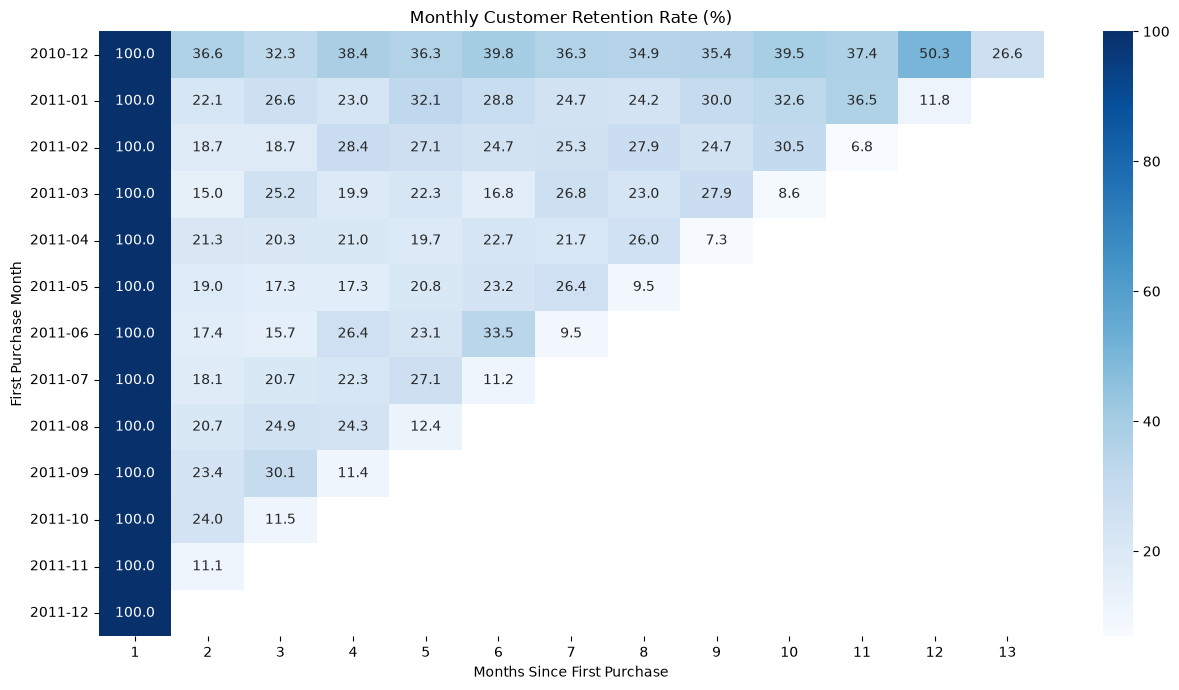

In [6]:

plt.figure(figsize=(13, 7))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=retention.isna()
)

plt.title("Monthly Customer Retention Rate (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Month")
plt.tight_layout()
plt.show()


In [7]:

# 기존 코호트 유지율 데이터 확인
print(retention.shape)

retention.tail()


(13, 13)


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2011-08,100.0,20.710059,24.852071,24.260355,12.426036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-09,100.0,23.411371,30.100334,11.371237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-10,100.0,24.022346,11.452514,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-11,100.0,11.145511,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-12,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

# 2011년 12월은 부분 월이므로 제외
retention_final = retention.copy()

# 각 코호트의 2011년 12월에 해당하는 칸을 제외
for cohort_month in retention_final.index:
    december_index = (
        (2011 - cohort_month.year) * 12
        + (12 - cohort_month.month)
        + 1
    )

    if december_index in retention_final.columns:
        retention_final.loc[
            cohort_month, december_index
        ] = float("nan")

# 2011년 12월 신규 코호트 제거
retention_final = retention_final[
    retention_final.index < pd.Period("2011-12", freq="M")
]

retention_final.round(2)


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,NaN
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,NaN,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,NaN,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,NaN,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,NaN,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,NaN,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


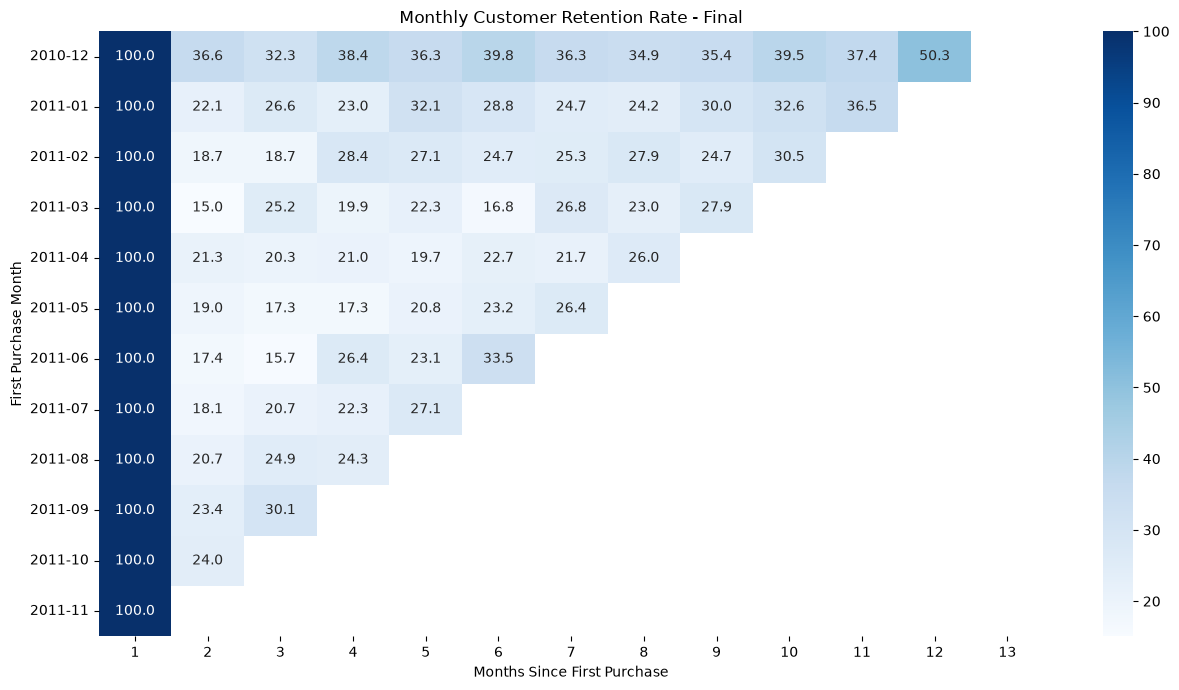

In [9]:

plt.figure(figsize=(13, 7))

sns.heatmap(
    retention_final,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=retention_final.isna()
)

plt.title("Monthly Customer Retention Rate - Final")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Month")
plt.tight_layout()
plt.show()


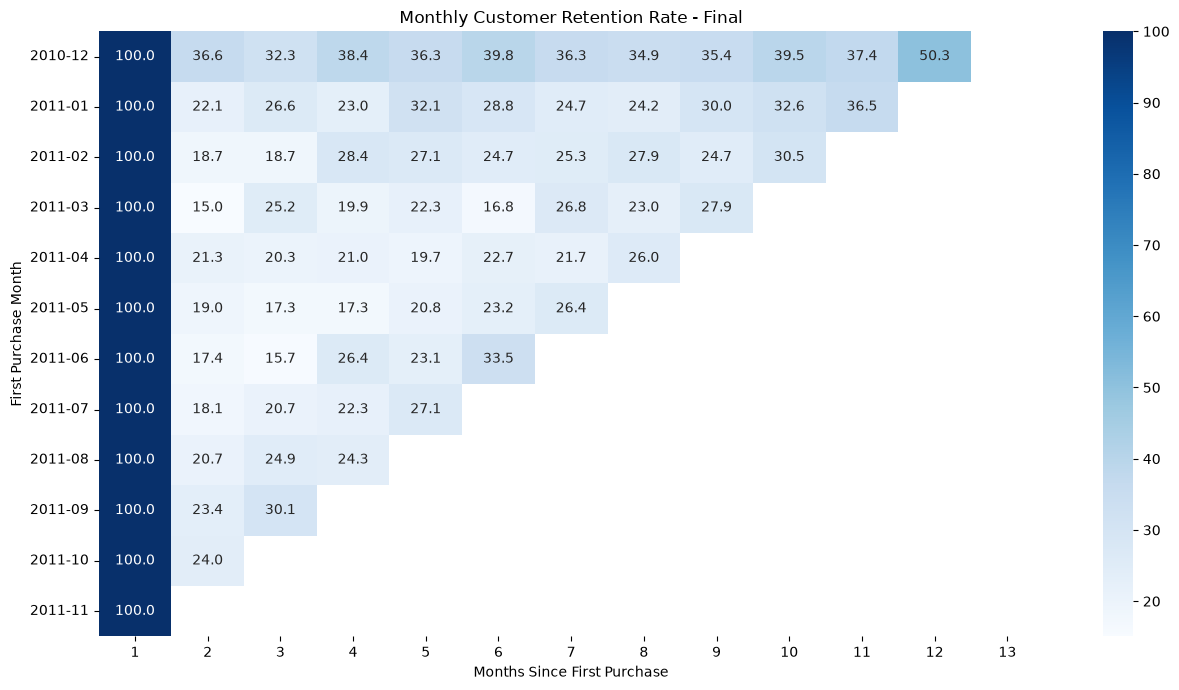

코호트 그래프 저장 완료


In [10]:

from pathlib import Path

# 저장 폴더 생성
Path("output").mkdir(exist_ok=True)

# 최종 코호트 히트맵 저장
plt.figure(figsize=(13, 7))

sns.heatmap(
    retention_final,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=retention_final.isna()
)

plt.title("Monthly Customer Retention Rate - Final")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Month")
plt.tight_layout()

plt.savefig(
    "output/cohort_retention_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("코호트 그래프 저장 완료")


In [11]:

retention_final.to_csv(
    "output/cohort_retention_final.csv",
    encoding="utf-8-sig"
)

print("코호트 분석표 저장 완료")


코호트 분석표 저장 완료
